In [1]:
# ============================================================
# Notebook 6: Explainability and Error Analysis
# Why do the attacks work? Saliency maps and confusion analysis
#
# Run notebook 4 first: this notebook uses the backdoored model it saves.
#
# CELL 1 - Setup (shared by every cell in this notebook)
# ============================================================

import os
import json
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from tqdm import tqdm

torch.manual_seed(42)
np.random.seed(42)

# -- Same SimpleCNN as in notebooks 1-3 --
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1   = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2   = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool    = nn.MaxPool2d(2, 2)
        self.relu    = nn.ReLU()
        self.fc1     = nn.Linear(64 * 7 * 7, 128)
        self.fc2     = nn.Linear(128, 10)
        self.dropout = nn.Dropout(0.25)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.view(-1, 64 * 7 * 7)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

# -- MNIST normalisation (same values as notebooks 1-3) --
MEAN, STD = 0.1307, 0.3081

# A real image has pixel values between 0 (black) and 1 (white).
# After normalisation those limits become X_MIN and X_MAX.
# Any image we create must stay inside this range to be a valid image.
X_MIN = (0.0 - MEAN) / STD
X_MAX = (1.0 - MEAN) / STD

def to_tensors(dataset):
    """Load a whole MNIST split into memory as normalised tensors.
    Gives exactly the same values as ToTensor() + Normalize(), but is much faster."""
    x = dataset.data.float().div(255).sub(MEAN).div(STD).unsqueeze(1)
    y = dataset.targets.clone()
    return x, y

def to_pixels(x):
    """Undo the normalisation: back to pixel values between 0 and 1."""
    return (x * STD + MEAN).clamp(0, 1)

train_set = torchvision.datasets.MNIST(root='../data', train=True,  download=False)
test_set  = torchvision.datasets.MNIST(root='../data', train=False, download=False)
X_train, y_train = to_tensors(train_set)
X_test,  y_test  = to_tensors(test_set)

def predict(model, X, batch_size=1000):
    """Return the model's raw outputs (logits) for a set of images."""
    model.eval()
    outputs = []
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            outputs.append(model(X[i:i + batch_size]))
    return torch.cat(outputs)

def accuracy(model, X, y):
    """Accuracy in percent."""
    return 100.0 * (predict(model, X).argmax(1) == y).float().mean().item()

def train_model(X, y, epochs=3, seed=0, batch_size=64, lr=0.001, desc="Training"):
    """Train a fresh SimpleCNN with the same settings as the baseline in notebook 1."""
    torch.manual_seed(seed)
    model = SimpleCNN()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    n = len(X)
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(n)
        for i in tqdm(range(0, n, batch_size), desc=f"{desc} epoch {epoch+1}/{epochs}"):
            idx = order[i:i + batch_size]
            optimizer.zero_grad()
            loss = criterion(model(X[idx]), y[idx])
            loss.backward()
            optimizer.step()
    model.eval()
    return model

def load_model(path):
    model = SimpleCNN()
    model.load_state_dict(torch.load(path, weights_only=True))
    model.eval()
    return model

os.makedirs('../figures', exist_ok=True)
os.makedirs('../results', exist_ok=True)
os.makedirs('../models',  exist_ok=True)

baseline_model = load_model('../models/mnist_cnn_baseline.pth')
print(f"Training images: {len(X_train)}   Test images: {len(X_test)}")
print(f"Baseline model clean accuracy: {accuracy(baseline_model, X_test, y_test):.2f}%")

Training images: 60000   Test images: 10000
Baseline model clean accuracy: 99.09%


Saliency maps for clean images (baseline model)


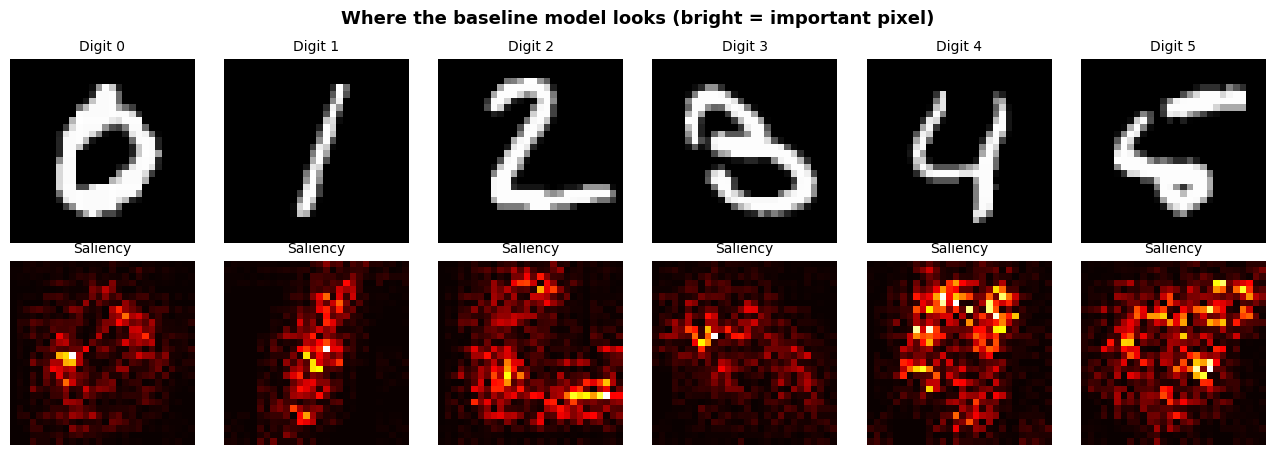

Saved: figures/saliency_clean.png


In [2]:
# CELL 2 - Saliency maps: which pixels does the model look at?
# Simonyan et al., "Deep Inside Convolutional Networks: Visualising Image
# Classification Models and Saliency Maps", 2014
#
# HOW IT WORKS:
# For one image and one class, we ask: "if I changed this pixel a little,
# how much would the score for that class change?" That is the gradient of
# the class score with respect to the input. Pixels with a large gradient
# are the ones the model's decision depends on most. Plotting them as a
# heat map gives a "saliency map".

EPSILON = 0.3   # attack strength in pixel units (0-1 scale), as in notebooks 2 and 3

def saliency_map(model, x, target_class):
    """Absolute gradient of each class score with respect to the input pixels."""
    model.eval()
    x = x.clone().requires_grad_(True)
    scores = model(x)
    chosen = scores.gather(1, target_class.view(-1, 1)).sum()
    grad, = torch.autograd.grad(chosen, x)
    return grad.abs().squeeze(1)

def fgsm_attack(model, x, y, epsilon):
    """FGSM. Epsilon is in pixel units; the result is clipped to the valid image range."""
    x = x.clone().requires_grad_(True)
    loss = nn.CrossEntropyLoss()(model(x), y)
    grad, = torch.autograd.grad(loss, x)
    return torch.clamp(x + (epsilon / STD) * grad.sign(), X_MIN, X_MAX).detach()

def pgd_attack(model, x, y, epsilon, steps=40):
    """PGD with step size epsilon / 10. Epsilon is in pixel units;
    the result is clipped to the valid image range."""
    eps_n, alpha_n = epsilon / STD, (epsilon / 10) / STD
    adv = torch.clamp(x + torch.empty_like(x).uniform_(-eps_n, eps_n), X_MIN, X_MAX)
    for _ in range(steps):
        adv.requires_grad_(True)
        loss = nn.CrossEntropyLoss()(model(adv), y)
        grad, = torch.autograd.grad(loss, adv)
        adv = x + torch.clamp(adv.detach() + alpha_n * grad.sign() - x, -eps_n, eps_n)
        adv = torch.clamp(adv, X_MIN, X_MAX).detach()
    return adv

def share_on_digit(saliency, x):
    """Share of the total saliency that falls on the digit's own strokes."""
    strokes = (to_pixels(x).squeeze(1) > 0.5).float()
    return (saliency * strokes).flatten(1).sum(1) / saliency.flatten(1).sum(1)

print("Saliency maps for clean images (baseline model)")
print("=" * 55)

examples = torch.tensor([int((y_test == d).nonzero()[0]) for d in range(6)])
x, y = X_test[examples], y_test[examples]
sal = saliency_map(baseline_model, x, y)

fig, axes = plt.subplots(2, 6, figsize=(13, 4.6))
for k in range(6):
    axes[0, k].imshow(to_pixels(x[k]).squeeze(), cmap='gray')
    axes[0, k].set_title(f"Digit {y[k].item()}", fontsize=10)
    axes[1, k].imshow(sal[k], cmap='hot')
    axes[1, k].set_title("Saliency", fontsize=10)
    axes[0, k].axis('off'); axes[1, k].axis('off')
fig.suptitle("Where the baseline model looks (bright = important pixel)",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../figures/saliency_clean.png', dpi=150)
plt.show()
print("Saved: figures/saliency_clean.png")

Saliency: clean vs adversarial (FGSM, baseline model)
FGSM (epsilon=0.3) fooled the model on 1782 of the first 2000 test images.

Share of saliency that lies on the digit strokes (average over fooled images):
  Clean images       : 30.9%
  Adversarial images : 21.0%


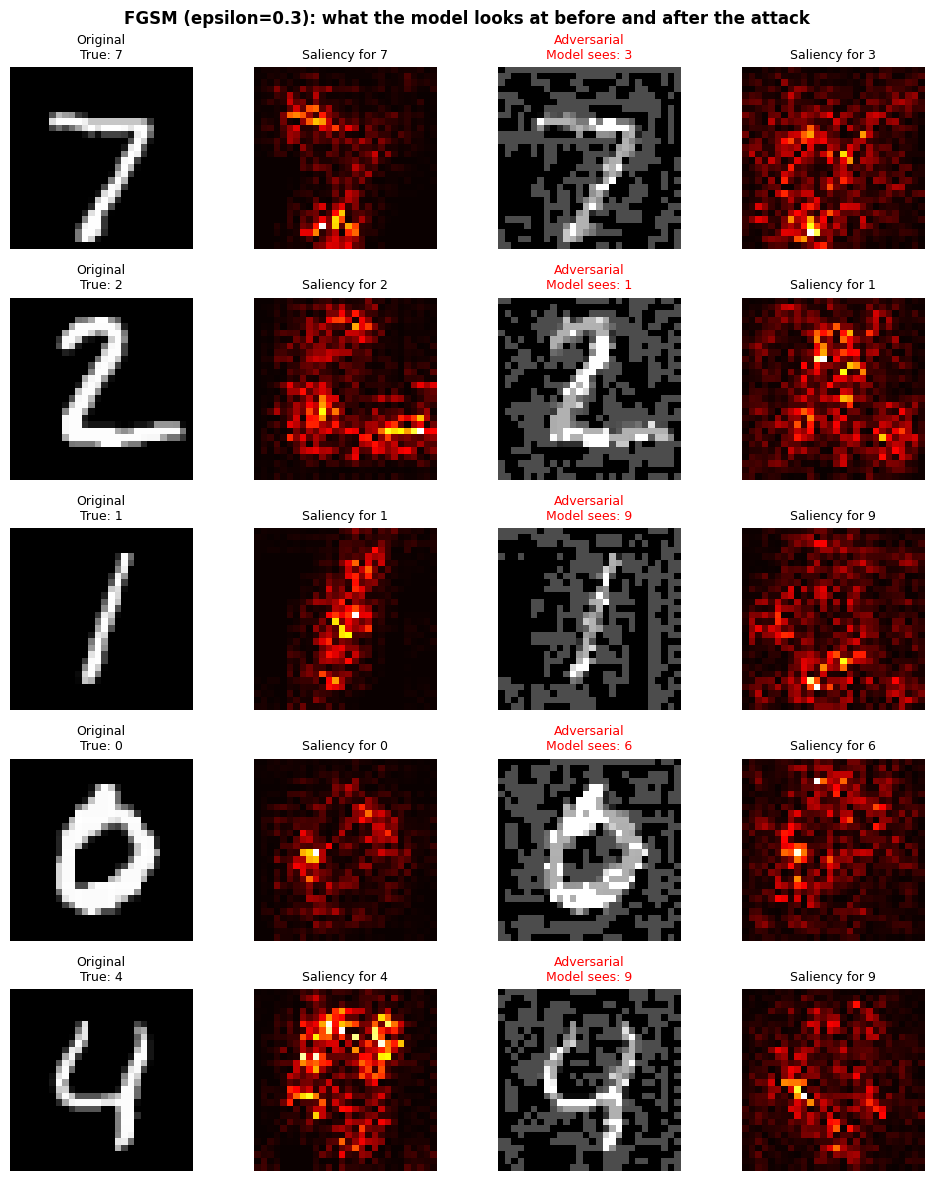

Saved: figures/saliency_clean_vs_adversarial.png


In [3]:
# CELL 3 - Clean vs adversarial: what changes inside the model?
#
# We take images that FGSM successfully fools and compare two saliency maps:
#   - clean image,        for the correct class
#   - adversarial image,  for the wrong class the model now predicts
# We also measure how much of the saliency lies on the digit's own strokes.

print("Saliency: clean vs adversarial (FGSM, baseline model)")
print("=" * 55)

N = 2000
x_all, y_all = X_test[:N], y_test[:N]
adv_all = torch.cat([fgsm_attack(baseline_model, x_all[i:i + 500], y_all[i:i + 500], EPSILON)
                     for i in range(0, N, 500)])
clean_pred = predict(baseline_model, x_all).argmax(1)
adv_pred   = predict(baseline_model, adv_all).argmax(1)
fooled = ((clean_pred == y_all) & (adv_pred != y_all)).nonzero().squeeze(1)
print(f"FGSM (epsilon={EPSILON}) fooled the model on {len(fooled)} of the first {N} test images.")

sal_clean = saliency_map(baseline_model, x_all[fooled],   y_all[fooled])
sal_adv   = saliency_map(baseline_model, adv_all[fooled], adv_pred[fooled])
on_digit_clean = 100.0 * share_on_digit(sal_clean, x_all[fooled]).mean().item()
on_digit_adv   = 100.0 * share_on_digit(sal_adv,   x_all[fooled]).mean().item()
print(f"\nShare of saliency that lies on the digit strokes (average over fooled images):")
print(f"  Clean images       : {on_digit_clean:.1f}%")
print(f"  Adversarial images : {on_digit_adv:.1f}%")

rows = min(5, len(fooled))
fig, axes = plt.subplots(rows, 4, figsize=(10, 2.4 * rows))
for r in range(rows):
    i = fooled[r]
    panels = [(to_pixels(x_all[i]).squeeze(),   'gray', f"Original\nTrue: {y_all[i].item()}"),
              (sal_clean[r],                    'hot',  f"Saliency for {y_all[i].item()}"),
              (to_pixels(adv_all[i]).squeeze(), 'gray', f"Adversarial\nModel sees: {adv_pred[i].item()}"),
              (sal_adv[r],                      'hot',  f"Saliency for {adv_pred[i].item()}")]
    for c, (img, cmap, title) in enumerate(panels):
        axes[r, c].imshow(img, cmap=cmap)
        axes[r, c].set_title(title, fontsize=9, color='red' if c == 2 else 'black')
        axes[r, c].axis('off')
fig.suptitle(f"FGSM (epsilon={EPSILON}): what the model looks at before and after the attack",
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../figures/saliency_clean_vs_adversarial.png', dpi=150)
plt.show()
print("Saved: figures/saliency_clean_vs_adversarial.png")

Error analysis under PGD
This cell takes roughly 1-3 minutes on CPU.



PGD: 100%|███████████████████████████████████████████████████████████████████████████████| 4/4 [00:21<00:00,  5.41s/it]



Accuracy under PGD (epsilon=0.3) on 2000 test images:
  Baseline model        : 0.00%
  Adversarially trained : 88.40%

Digit     Baseline   Adv. trained
---------------------------------
0             0.0%          98.3%
1             0.0%          96.6%
2             0.0%          93.6%
3             0.0%          87.9%
4             0.0%          87.1%
5             0.0%          88.3%
6             0.0%          89.3%
7             0.0%          84.4%
8             0.0%          72.4%
9             0.0%          85.1%

Most common mistakes of the baseline model under PGD:
  true 4 -> predicted 9: 152 images
  true 2 -> predicted 3: 129 images
  true 7 -> predicted 3: 111 images
  true 8 -> predicted 3: 96 images
  true 5 -> predicted 3: 92 images


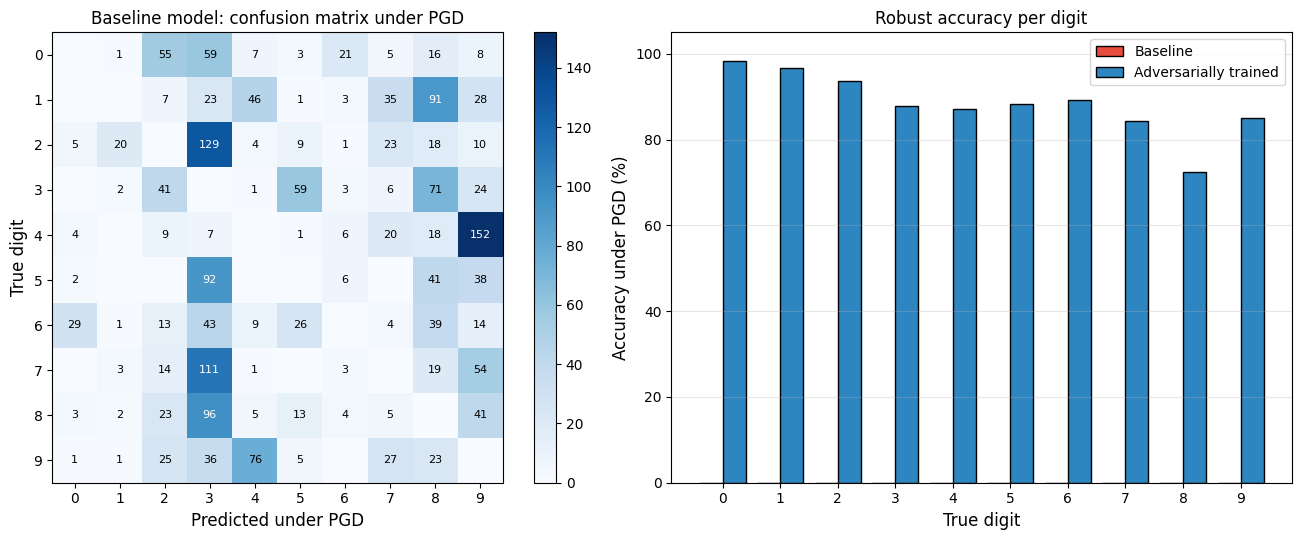

Saved: figures/error_analysis_pgd.png


In [4]:
# CELL 4 - Error analysis: which digits are fooled, and into what?
#
# We run PGD on 2,000 test images and record, for every true digit,
# which digit the model predicts under attack (a "confusion matrix").
# We also compare robust accuracy per digit for the baseline and the
# adversarially trained model.

print("Error analysis under PGD")
print("=" * 55)
print("This cell takes roughly 1-3 minutes on CPU.\n")

adv_trained_model = load_model('../models/mnist_adversarial_trained.pth')

def pgd_predictions(model, x, y):
    torch.manual_seed(0)
    adv = torch.cat([pgd_attack(model, x[i:i + 500], y[i:i + 500], EPSILON)
                     for i in tqdm(range(0, len(x), 500), desc="PGD")])
    return predict(model, adv).argmax(1)

pgd_pred_base = pgd_predictions(baseline_model,    x_all, y_all)
pgd_pred_adv  = pgd_predictions(adv_trained_model, x_all, y_all)

def per_class_accuracy(pred, y):
    return [100.0 * (pred[y == d] == d).float().mean().item() for d in range(10)]

acc_base = per_class_accuracy(pgd_pred_base, y_all)
acc_adv  = per_class_accuracy(pgd_pred_adv,  y_all)
overall_base = 100.0 * (pgd_pred_base == y_all).float().mean().item()
overall_adv  = 100.0 * (pgd_pred_adv  == y_all).float().mean().item()

print(f"\nAccuracy under PGD (epsilon={EPSILON}) on {N} test images:")
print(f"  Baseline model        : {overall_base:.2f}%")
print(f"  Adversarially trained : {overall_adv:.2f}%\n")
print(f"{'Digit':<7} {'Baseline':>10} {'Adv. trained':>14}")
print("-" * 33)
for d in range(10):
    print(f"{d:<7} {acc_base[d]:>9.1f}% {acc_adv[d]:>13.1f}%")

confusion = torch.zeros(10, 10, dtype=torch.long)
for t, p in zip(y_all, pgd_pred_base):
    confusion[t, p] += 1
off_diagonal = confusion.clone()
off_diagonal.fill_diagonal_(0)
top_pairs = []
for flat in off_diagonal.flatten().argsort(descending=True)[:5]:
    t, p = divmod(flat.item(), 10)
    if off_diagonal[t, p] > 0:
        top_pairs.append((t, p, off_diagonal[t, p].item()))
print("\nMost common mistakes of the baseline model under PGD:")
for t, p, count in top_pairs:
    print(f"  true {t} -> predicted {p}: {count} images")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
im = axes[0].imshow(confusion, cmap='Blues')
for t in range(10):
    for p in range(10):
        v = confusion[t, p].item()
        if v:
            axes[0].text(p, t, v, ha='center', va='center', fontsize=8,
                         color='white' if v > confusion.max().item() / 2 else 'black')
axes[0].set_xticks(range(10)); axes[0].set_yticks(range(10))
axes[0].set_xlabel('Predicted under PGD', fontsize=12)
axes[0].set_ylabel('True digit', fontsize=12)
axes[0].set_title('Baseline model: confusion matrix under PGD', fontsize=12)
plt.colorbar(im, ax=axes[0], fraction=0.046)

pos = np.arange(10)
axes[1].bar(pos - 0.2, acc_base, 0.4, label='Baseline', color='#e74c3c', edgecolor='black')
axes[1].bar(pos + 0.2, acc_adv,  0.4, label='Adversarially trained',
            color='#2e86c1', edgecolor='black')
axes[1].set_xticks(pos)
axes[1].set_xlabel('True digit', fontsize=12)
axes[1].set_ylabel('Accuracy under PGD (%)', fontsize=12)
axes[1].set_title('Robust accuracy per digit', fontsize=12)
axes[1].set_ylim(0, 105)
axes[1].legend(fontsize=10)
axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/error_analysis_pgd.png', dpi=150)
plt.show()
print("Saved: figures/error_analysis_pgd.png")

Saliency on images carrying the backdoor trigger
Triggered images classified as 0 by the backdoored model: 100.0%

Share of saliency inside the 3x3 trigger area (the area is 1.1% of the image):
  Backdoored model : 27.4%
  Baseline model   : 1.9%


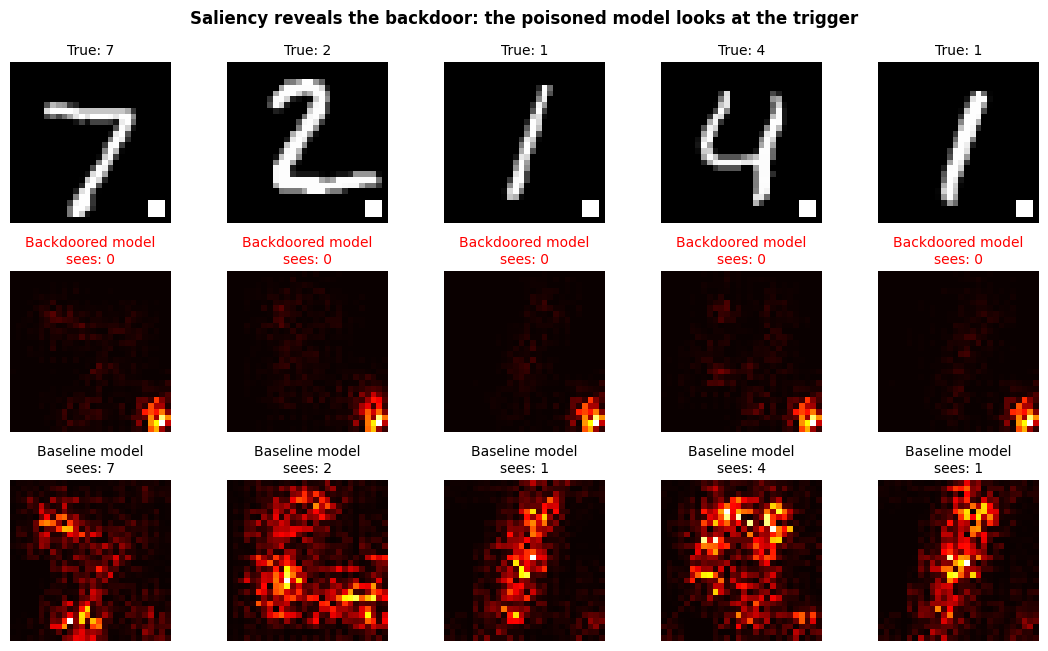

Saved: figures/saliency_backdoor.png


In [5]:
# CELL 5 - Explaining the backdoor
#
# The backdoored model from notebook 4 classifies any image with the corner
# trigger as class 0. If the explanation method is useful, the saliency map
# of the backdoored model should light up on the trigger, while the clean
# baseline model should ignore that corner.

backdoor_path = '../models/mnist_backdoored.pth'
trigger_share_backdoored = trigger_share_baseline = None

if not os.path.exists(backdoor_path):
    print("models/mnist_backdoored.pth not found - run notebook 4 first, then re-run this cell.")
else:
    print("Saliency on images carrying the backdoor trigger")
    print("=" * 55)
    backdoored_model = load_model(backdoor_path)

    def add_trigger(x):
        x = x.clone()
        x[:, :, 24:27, 24:27] = X_MAX
        return x

    keep = (y_all != 0).nonzero().squeeze(1)[:500]
    triggered = add_trigger(x_all[keep])
    pred_bd   = predict(backdoored_model, triggered).argmax(1)
    pred_base = predict(baseline_model,   triggered).argmax(1)

    sal_bd   = saliency_map(backdoored_model, triggered, pred_bd)
    sal_base = saliency_map(baseline_model,   triggered, pred_base)

    def share_on_trigger(saliency):
        return 100.0 * (saliency[:, 24:27, 24:27].flatten(1).sum(1) /
                        saliency.flatten(1).sum(1)).mean().item()

    trigger_share_backdoored = share_on_trigger(sal_bd)
    trigger_share_baseline   = share_on_trigger(sal_base)
    print(f"Triggered images classified as 0 by the backdoored model: "
          f"{100.0 * (pred_bd == 0).float().mean().item():.1f}%")
    print(f"\nShare of saliency inside the 3x3 trigger area "
          f"(the area is {100.0 * 9 / 784:.1f}% of the image):")
    print(f"  Backdoored model : {trigger_share_backdoored:.1f}%")
    print(f"  Baseline model   : {trigger_share_baseline:.1f}%")

    fig, axes = plt.subplots(3, 5, figsize=(11, 6.6))
    for k in range(5):
        axes[0, k].imshow(to_pixels(triggered[k]).squeeze(), cmap='gray')
        axes[0, k].set_title(f"True: {y_all[keep[k]].item()}", fontsize=10)
        axes[1, k].imshow(sal_bd[k], cmap='hot')
        axes[1, k].set_title(f"Backdoored model\nsees: {pred_bd[k].item()}",
                             fontsize=10, color='red')
        axes[2, k].imshow(sal_base[k], cmap='hot')
        axes[2, k].set_title(f"Baseline model\nsees: {pred_base[k].item()}", fontsize=10)
        for r in range(3):
            axes[r, k].axis('off')
    fig.suptitle("Saliency reveals the backdoor: the poisoned model looks at the trigger",
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig('../figures/saliency_backdoor.png', dpi=150)
    plt.show()
    print("Saved: figures/saliency_backdoor.png")

In [6]:
# CELL 6 - Save the findings of this notebook

with open('../results/explainability_results.txt', 'w') as f:
    f.write("Explainability and Error Analysis Results\n")
    f.write("=" * 45 + "\n\n")
    f.write(f"FGSM (epsilon={EPSILON}) fooled the baseline model on "
            f"{len(fooled)} of {N} test images\n")
    f.write(f"Saliency on digit strokes, clean images      : {on_digit_clean:.1f}%\n")
    f.write(f"Saliency on digit strokes, adversarial images: {on_digit_adv:.1f}%\n\n")
    f.write(f"Accuracy under PGD (epsilon={EPSILON}, {N} images)\n")
    f.write(f"  Baseline model        : {overall_base:.2f}%\n")
    f.write(f"  Adversarially trained : {overall_adv:.2f}%\n")
    f.write("  Per digit (baseline / adversarially trained):\n")
    for d in range(10):
        f.write(f"    {d}: {acc_base[d]:.1f}% / {acc_adv[d]:.1f}%\n")
    f.write("  Most common baseline mistakes under PGD:\n")
    for t, p, count in top_pairs:
        f.write(f"    true {t} -> predicted {p}: {count} images\n")
    if trigger_share_backdoored is not None:
        f.write("\nShare of saliency inside the backdoor trigger area "
                "(area = 1.1% of the image)\n")
        f.write(f"  Backdoored model : {trigger_share_backdoored:.1f}%\n")
        f.write(f"  Baseline model   : {trigger_share_baseline:.1f}%\n")

print("Explainability results saved to results/explainability_results.txt")
print("\nAll figures saved to figures/")

Explainability results saved to results/explainability_results.txt

All figures saved to figures/
